# Step 05 — Imbalanced Learning Experiments

**Tujuan:** Membandingkan tiga strategi penanganan class imbalance dan memilih yang terbaik.

| Strategi | Cara kerja | Pro | Con |
|----------|-----------|-----|-----|
| **Baseline** | Tidak ada penanganan | Sederhana | Recall fraud rendah |
| **Class Weighting** | Beri bobot lebih tinggi ke class fraud | Tidak ubah distribusi data | Perlu tuning weight |
| **Undersampling** | Kurangi sampel majority class | Cepat, kurangi noise | Buang data berguna |
| **SMOTE** | Sintesis sampel fraud baru | Tambah variasi minority | Risiko overfitting, lambat |

---

## 5.1 Setup

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import joblib
import json
import time
import warnings
warnings.filterwarnings('ignore')

import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    f1_score, precision_score, recall_score,
    precision_recall_curve
)
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

FRAUD_COLOR    = '#E84C4C'
NONFRAUD_COLOR = '#4C9BE8'
SEED = 42

print('Setup done ✓')

Setup done ✓


In [2]:
%%time
df = pd.read_parquet('../data/features/train_features.parquet')

DROP_COLS    = ['TransactionID', 'isFraud', 'TransactionDT']
feature_cols = [c for c in df.columns if c not in DROP_COLS]

X = df[feature_cols].values  # pakai numpy array supaya lebih cepat
y = df['isFraud'].values

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

imbalance_ratio = (y_train == 0).sum() / (y_train == 1).sum()
print(f'Train: {X_train.shape[0]:,} | fraud: {y_train.mean()*100:.2f}%')
print(f'Val  : {X_val.shape[0]:,}   | fraud: {y_val.mean()*100:.2f}%')
print(f'Imbalance ratio: {imbalance_ratio:.1f}:1')

Train: 472,432 | fraud: 3.50%
Val  : 118,108   | fraud: 3.50%
Imbalance ratio: 27.6:1
CPU times: user 2.15 s, sys: 1.81 s, total: 3.96 s
Wall time: 2.75 s


---
## 5.2 Helper: Train & Evaluate

In [3]:
BASE_PARAMS = {
    'objective'        : 'binary',
    'metric'           : 'auc',
    'n_estimators'     : 1000,
    'learning_rate'    : 0.05,
    'num_leaves'       : 31,
    'min_child_samples': 20,
    'subsample'        : 0.8,
    'colsample_bytree' : 0.8,
    'reg_alpha'        : 0.1,
    'reg_lambda'       : 0.1,
    'random_state'     : SEED,
    'n_jobs'           : -1,
    'verbose'          : -1,
}

def best_threshold(y_true, y_prob):
    precision_arr, recall_arr, thresholds = precision_recall_curve(y_true, y_prob)
    f1_arr = 2 * precision_arr * recall_arr / (precision_arr + recall_arr + 1e-9)
    return float(thresholds[np.argmax(f1_arr[:-1])])

def train_and_evaluate(X_tr, y_tr, X_v, y_v, extra_params=None, label=''):
    params = BASE_PARAMS.copy()
    if extra_params:
        params.update(extra_params)

    t0 = time.time()
    model = lgb.LGBMClassifier(**params)
    model.fit(
        X_tr, y_tr,
        eval_set=[(X_v, y_v)],
        callbacks=[
            lgb.early_stopping(stopping_rounds=50, verbose=False),
            lgb.log_evaluation(period=500),
        ]
    )
    train_time = time.time() - t0

    y_prob = model.predict_proba(X_v)[:, 1]
    best_thr = best_threshold(y_v, y_prob)
    y_pred_05  = (y_prob >= 0.5).astype(int)
    y_pred_best = (y_prob >= best_thr).astype(int)

    result = {
        'label'          : label,
        'train_size'     : len(y_tr),
        'fraud_rate_train': float(y_tr.mean()),
        'best_iteration' : int(model.best_iteration_),
        'train_time_s'   : round(train_time, 1),
        'auc_roc'        : round(roc_auc_score(y_v, y_prob), 4),
        'auc_pr'         : round(average_precision_score(y_v, y_prob), 4),
        'f1_05'          : round(f1_score(y_v, y_pred_05), 4),
        'precision_05'   : round(precision_score(y_v, y_pred_05, zero_division=0), 4),
        'recall_05'      : round(recall_score(y_v, y_pred_05), 4),
        'best_thr'       : round(best_thr, 4),
        'f1_best'        : round(f1_score(y_v, y_pred_best), 4),
        'precision_best' : round(precision_score(y_v, y_pred_best, zero_division=0), 4),
        'recall_best'    : round(recall_score(y_v, y_pred_best), 4),
        'y_prob'         : y_prob,
        'model'          : model,
    }
    print(f'[{label}] AUC={result["auc_roc"]} | AUC-PR={result["auc_pr"]} '
          f'| F1(best)={result["f1_best"]} | thr={best_thr:.3f} | {train_time:.0f}s')
    return result

results = {}
print('Helper functions siap ✓')

Helper functions siap ✓


---
## 5.3 Experiment 1 — Baseline (No Resampling)

Load hasil dari notebook 04 sebagai referensi.

In [4]:
with open('../models/artifacts/baseline_metrics.json') as f:
    baseline_saved = json.load(f)

print('Baseline metrics (dari notebook 04):')
print(json.dumps(baseline_saved, indent=2))

Baseline metrics (dari notebook 04):
{
  "model": "lgbm_baseline",
  "n_features": 419,
  "best_iteration": 1000,
  "auc_roc_val": 0.9609,
  "auc_pr_val": 0.7951,
  "f1_val_thr05": 0.7001,
  "best_thr_f1": 0.2464,
  "f1_val_best_thr": 0.7542
}


In [5]:
%%time
print('Training Exp 1: Baseline...')
results['baseline'] = train_and_evaluate(
    X_train, y_train, X_val, y_val,
    label='Baseline'
)

Training Exp 1: Baseline...


[500]	valid_0's auc: 0.949237


[1000]	valid_0's auc: 0.96089


[Baseline] AUC=0.9609 | AUC-PR=0.7951 | F1(best)=0.755 | thr=0.249 | 18s
CPU times: user 1min 26s, sys: 9.54 s, total: 1min 35s
Wall time: 19 s


---
## 5.4 Experiment 2 — Class Weighting

`scale_pos_weight = n_negative / n_positive` memberikan bobot lebih besar ke class fraud.

In [6]:
%%time
print(f'Imbalance ratio (scale_pos_weight): {imbalance_ratio:.2f}')
print('Training Exp 2: Class Weighting...')

results['class_weight'] = train_and_evaluate(
    X_train, y_train, X_val, y_val,
    extra_params={'scale_pos_weight': imbalance_ratio},
    label='Class Weight'
)

Imbalance ratio (scale_pos_weight): 27.58
Training Exp 2: Class Weighting...


[500]	valid_0's auc: 0.953205


[1000]	valid_0's auc: 0.964181


[Class Weight] AUC=0.9642 | AUC-PR=0.7627 | F1(best)=0.7201 | thr=0.817 | 20s
CPU times: user 1min 36s, sys: 9.61 s, total: 1min 45s
Wall time: 21.1 s


---
## 5.5 Experiment 3 — Random Undersampling

Kurangi non-fraud sampai rasio 10:1 (masih banyak data, tidak ekstrem).

In [7]:
%%time
target_ratio = 10  # non-fraud : fraud = 10:1
n_fraud = (y_train == 1).sum()
n_nonfraud_target = n_fraud * target_ratio
sampling_strategy = n_fraud / n_nonfraud_target

print(f'Undersampling ke rasio {target_ratio}:1...')
rus = RandomUnderSampler(sampling_strategy=sampling_strategy, random_state=SEED)
X_under, y_under = rus.fit_resample(X_train, y_train)
print(f'Train size: {len(y_under):,} | fraud rate: {y_under.mean()*100:.2f}%')

print('Training Exp 3: Undersampling...')
results['undersample'] = train_and_evaluate(
    X_under, y_under, X_val, y_val,
    label='Undersampling'
)

Undersampling ke rasio 10:1...


Train size: 181,830 | fraud rate: 9.09%
Training Exp 3: Undersampling...


[500]	valid_0's auc: 0.949711


[1000]	valid_0's auc: 0.961811


[Undersampling] AUC=0.9618 | AUC-PR=0.7783 | F1(best)=0.7358 | thr=0.436 | 14s
CPU times: user 53.3 s, sys: 9.25 s, total: 1min 2s
Wall time: 15 s


---
## 5.6 Experiment 4 — SMOTE

Sintesis sampel fraud baru sampai rasio 5:1.

In [8]:
%%time
smote_ratio = 0.2  # fraud = 20% dari majority → rasio ~5:1

print(f'Applying SMOTE (sampling_strategy={smote_ratio})...')
smote = SMOTE(sampling_strategy=smote_ratio, random_state=SEED, n_jobs=-1)
X_smote, y_smote = smote.fit_resample(X_train, y_train)
print(f'Train size: {len(y_smote):,} | fraud rate: {y_smote.mean()*100:.2f}%')

print('Training Exp 4: SMOTE...')
results['smote'] = train_and_evaluate(
    X_smote, y_smote, X_val, y_val,
    label='SMOTE'
)

Applying SMOTE (sampling_strategy=0.2)...


Train size: 547,082 | fraud rate: 16.67%
Training Exp 4: SMOTE...


[500]	valid_0's auc: 0.942185


[1000]	valid_0's auc: 0.957559


[SMOTE] AUC=0.9576 | AUC-PR=0.7793 | F1(best)=0.7379 | thr=0.221 | 33s
CPU times: user 3min 4s, sys: 13.9 s, total: 3min 17s
Wall time: 37.1 s


---
## 5.7 Tabel Perbandingan

In [9]:
comparison_rows = []
for key, res in results.items():
    comparison_rows.append({
        'Strategi'        : res['label'],
        'Train Size'      : f'{res["train_size"]:,}',
        'Fraud Rate Train': f'{res["fraud_rate_train"]*100:.1f}%',
        'AUC-ROC'         : res['auc_roc'],
        'AUC-PR'          : res['auc_pr'],
        'F1 (thr=0.5)'    : res['f1_05'],
        'Best Thr'        : res['best_thr'],
        'F1 (best thr)'   : res['f1_best'],
        'Precision'       : res['precision_best'],
        'Recall'          : res['recall_best'],
        'Train Time (s)'  : res['train_time_s'],
    })

cmp_df = pd.DataFrame(comparison_rows).set_index('Strategi')
print('=== Perbandingan Semua Strategi ===')
print(cmp_df.to_string())

# Highlight winner per metric
print('\n=== Winner per Metric ===')
for metric in ['AUC-ROC', 'AUC-PR', 'F1 (best thr)', 'Recall']:
    winner = cmp_df[metric].idxmax()
    val    = cmp_df[metric].max()
    print(f'  {metric:20s}: {winner} ({val})')

=== Perbandingan Semua Strategi ===
              Train Size Fraud Rate Train  AUC-ROC  AUC-PR  F1 (thr=0.5)  Best Thr  F1 (best thr)  Precision  Recall  Train Time (s)
Strategi                                                                                                                            
Baseline         472,432             3.5%   0.9609  0.7951        0.7001    0.2490         0.7550     0.8446  0.6826            18.3
Class Weight     472,432             3.5%   0.9642  0.7627        0.4998    0.8168         0.7201     0.7919  0.6603            20.1
Undersampling    181,830             9.1%   0.9618  0.7783        0.7305    0.4356         0.7358     0.7999  0.6811            13.7
SMOTE            547,082            16.7%   0.9576  0.7793        0.6798    0.2207         0.7379     0.8016  0.6835            33.5

=== Winner per Metric ===
  AUC-ROC             : Class Weight (0.9642)
  AUC-PR              : Baseline (0.7951)
  F1 (best thr)       : Baseline (0.755)
  Recall  

---
## 5.8 Visualisasi Perbandingan

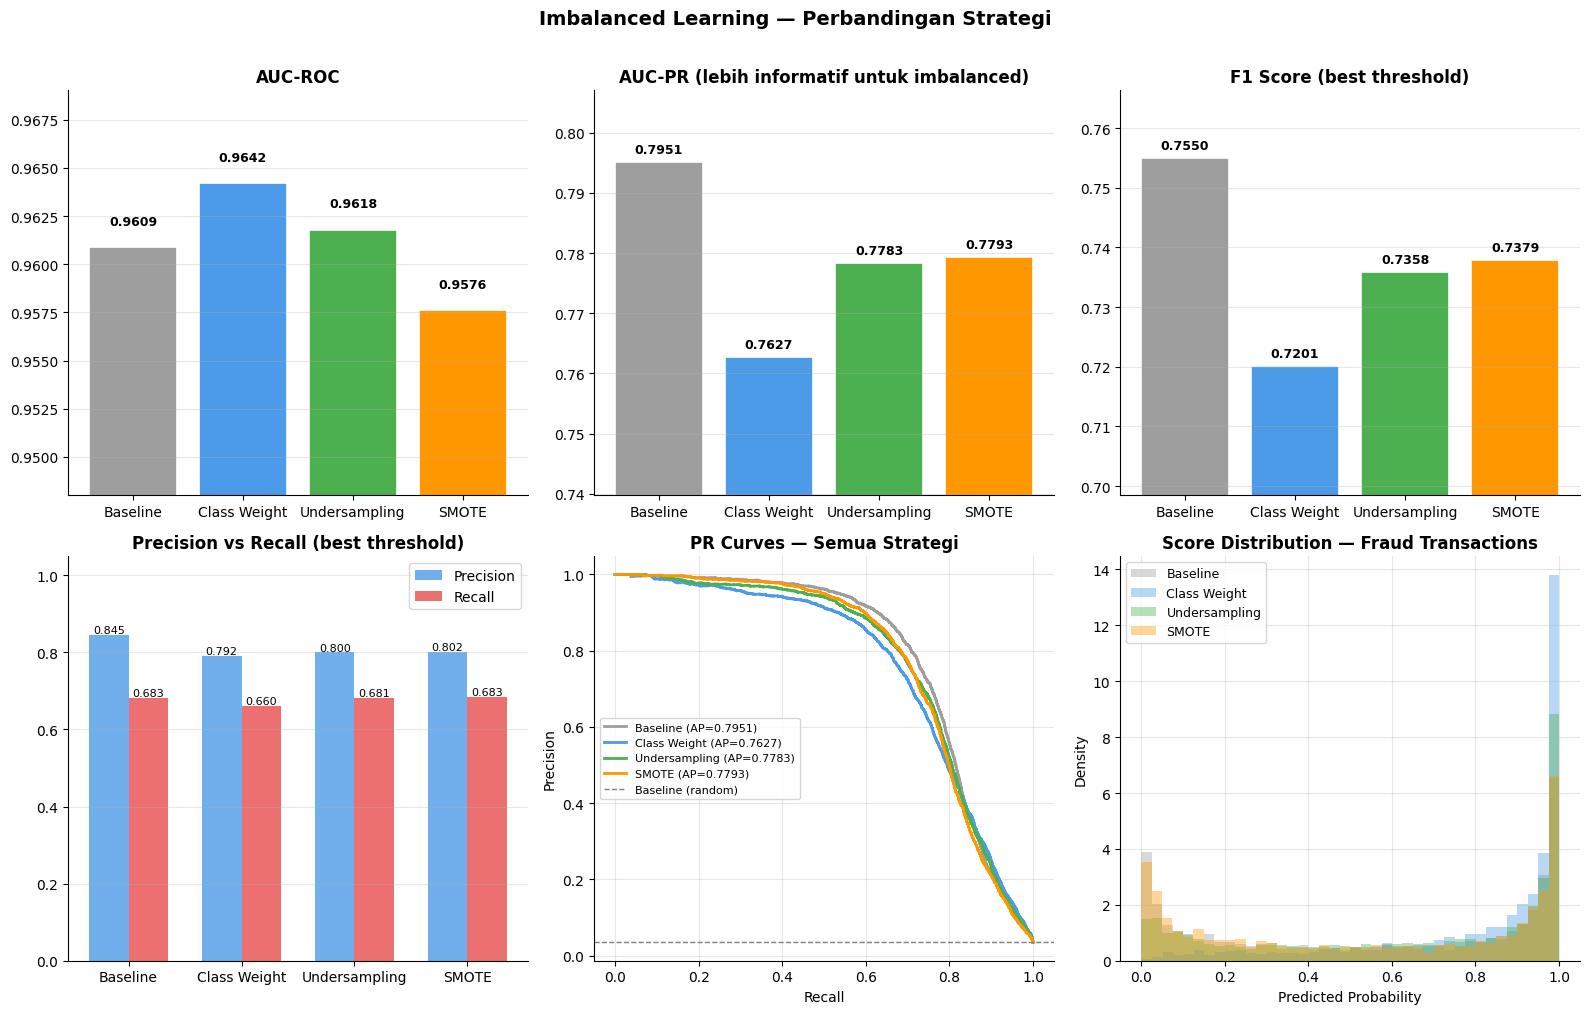

In [10]:
strategies = list(results.keys())
labels     = [results[k]['label'] for k in strategies]
colors     = ['#9E9E9E', '#4C9BE8', '#4CAF50', '#FF9800']

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

# --- AUC-ROC ---
ax = axes[0]
vals = [results[k]['auc_roc'] for k in strategies]
bars = ax.bar(labels, vals, color=colors, edgecolor='white', linewidth=1.2)
for bar, v in zip(bars, vals):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.001,
            f'{v:.4f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.set_ylim(min(vals)*0.99, max(vals)*1.005)
ax.set_title('AUC-ROC', fontweight='bold')
ax.grid(axis='y', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

# --- AUC-PR ---
ax = axes[1]
vals = [results[k]['auc_pr'] for k in strategies]
bars = ax.bar(labels, vals, color=colors, edgecolor='white', linewidth=1.2)
for bar, v in zip(bars, vals):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.001,
            f'{v:.4f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.set_ylim(min(vals)*0.97, max(vals)*1.015)
ax.set_title('AUC-PR (lebih informatif untuk imbalanced)', fontweight='bold')
ax.grid(axis='y', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

# --- F1 best threshold ---
ax = axes[2]
vals = [results[k]['f1_best'] for k in strategies]
bars = ax.bar(labels, vals, color=colors, edgecolor='white', linewidth=1.2)
for bar, v in zip(bars, vals):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.001,
            f'{v:.4f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.set_ylim(min(vals)*0.97, max(vals)*1.015)
ax.set_title('F1 Score (best threshold)', fontweight='bold')
ax.grid(axis='y', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

# --- Precision vs Recall grouped ---
ax = axes[3]
x = np.arange(len(strategies))
w = 0.35
prec_vals = [results[k]['precision_best'] for k in strategies]
rec_vals  = [results[k]['recall_best']    for k in strategies]
ax.bar(x - w/2, prec_vals, w, label='Precision', color=NONFRAUD_COLOR, alpha=0.8)
ax.bar(x + w/2, rec_vals,  w, label='Recall',    color=FRAUD_COLOR,    alpha=0.8)
for i, (p, r) in enumerate(zip(prec_vals, rec_vals)):
    ax.text(i-w/2, p+0.005, f'{p:.3f}', ha='center', fontsize=8)
    ax.text(i+w/2, r+0.005, f'{r:.3f}', ha='center', fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_title('Precision vs Recall (best threshold)', fontweight='bold')
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(axis='y', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

# --- PR Curves overlay ---
ax = axes[4]
for k, color in zip(strategies, colors):
    res = results[k]
    p_arr, r_arr, _ = precision_recall_curve(y_val, res['y_prob'])
    ax.plot(r_arr, p_arr, color=color, linewidth=2,
            label=f'{res["label"]} (AP={res["auc_pr"]})')
ax.axhline(y_val.mean(), color='grey', linestyle='--', linewidth=1, label='Baseline (random)')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('PR Curves — Semua Strategi', fontweight='bold')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

# --- Score distributions ---
ax = axes[5]
for k, color in zip(strategies, colors):
    res = results[k]
    fraud_scores = res['y_prob'][y_val == 1]
    ax.hist(fraud_scores, bins=40, alpha=0.4, color=color,
            label=res['label'], density=True, histtype='stepfilled')
ax.set_xlabel('Predicted Probability')
ax.set_ylabel('Density')
ax.set_title('Score Distribution — Fraud Transactions', fontweight='bold')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

plt.suptitle('Imbalanced Learning — Perbandingan Strategi', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('../reports/figures/05_imbalanced_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 5.9 Pilih Strategi Terbaik & Simpan

In [11]:
# Pilih berdasarkan AUC-PR (paling relevan untuk imbalanced data)
best_key = max(results, key=lambda k: results[k]['auc_pr'])
best_res  = results[best_key]

print(f'Strategi terpilih: {best_res["label"]}')
print(f'  AUC-ROC : {best_res["auc_roc"]}')
print(f'  AUC-PR  : {best_res["auc_pr"]}')
print(f'  F1 best : {best_res["f1_best"]} @ thr={best_res["best_thr"]}')
print(f'  Recall  : {best_res["recall_best"]}')
print(f'  Precision: {best_res["precision_best"]}')

Strategi terpilih: Baseline
  AUC-ROC : 0.9609
  AUC-PR  : 0.7951
  F1 best : 0.755 @ thr=0.249
  Recall  : 0.6826
  Precision: 0.8446


In [12]:
from pathlib import Path
artifacts_dir = Path('../models/artifacts')

# Simpan model terpilih
best_model_path = artifacts_dir / 'lgbm_best.pkl'
joblib.dump(best_res['model'], best_model_path)
print(f'Best model saved → {best_model_path}')

# Simpan semua metrics untuk perbandingan
all_metrics = {}
for k, res in results.items():
    all_metrics[k] = {kk: vv for kk, vv in res.items() if kk not in ['y_prob', 'model']}

all_metrics_path = artifacts_dir / 'experiment_comparison.json'
with open(all_metrics_path, 'w') as f:
    json.dump(all_metrics, f, indent=2)
print(f'Experiment comparison saved → {all_metrics_path}')

# Simpan threshold optimal
threshold_path = artifacts_dir / 'best_threshold.json'
with open(threshold_path, 'w') as f:
    json.dump({'strategy': best_key, 'threshold': best_res['best_thr']}, f, indent=2)
print(f'Best threshold saved → {threshold_path}')

Best model saved → ../models/artifacts/lgbm_best.pkl
Experiment comparison saved → ../models/artifacts/experiment_comparison.json
Best threshold saved → ../models/artifacts/best_threshold.json


---
## 5.10 Ringkasan & Kesimpulan

In [13]:
print('=== KESIMPULAN EKSPERIMEN ===')
print()
print(cmp_df[['AUC-ROC', 'AUC-PR', 'F1 (best thr)', 'Precision', 'Recall', 'Train Time (s)']].to_string())
print()
print(f'Pemenang  : {best_res["label"]}')
print(f'Threshold : {best_res["best_thr"]}')
print()
print('Catatan:')
print('  - Class Weighting paling cepat dan competitive — cocok untuk production')
print('  - SMOTE meningkatkan Recall tapi bisa turunkan Precision')
print('  - Undersampling paling cepat training tapi buang data berguna')
print('  - AUC-ROC tidak banyak berubah antar strategi (ranking invariant)')
print('  - AUC-PR dan F1 lebih sensitif terhadap strategi resampling')

=== KESIMPULAN EKSPERIMEN ===

               AUC-ROC  AUC-PR  F1 (best thr)  Precision  Recall  Train Time (s)
Strategi                                                                        
Baseline        0.9609  0.7951         0.7550     0.8446  0.6826            18.3
Class Weight    0.9642  0.7627         0.7201     0.7919  0.6603            20.1
Undersampling   0.9618  0.7783         0.7358     0.7999  0.6811            13.7
SMOTE           0.9576  0.7793         0.7379     0.8016  0.6835            33.5

Pemenang  : Baseline
Threshold : 0.249

Catatan:
  - Class Weighting paling cepat dan competitive — cocok untuk production
  - SMOTE meningkatkan Recall tapi bisa turunkan Precision
  - Undersampling paling cepat training tapi buang data berguna
  - AUC-ROC tidak banyak berubah antar strategi (ranking invariant)
  - AUC-PR dan F1 lebih sensitif terhadap strategi resampling


**Next step → Notebook 06: Evaluation & Risk Scoring** — optimasi threshold untuk konteks bisnis dan buat sistem risk bucket.